In [1]:
#!pip install torch torchvision torchaudio numpy opencv-python-headless

In [2]:
#!pip install --upgrade pip

In [3]:
#!pip install ultralytics

In [4]:
#!pip install yolov5

In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO

import winsound  # For sound alerts (Windows users)

In [6]:
from ultralytics import YOLO

# Load the YOLOv5 model
model = YOLO(r"C:\Users\Lokesh Patra\Documents\Projects\IBM ICE Day 3\yolov5xu.pt")

# Print model info
print(model)

YOLO(
  (model): DetectionModel(
    (model): Sequential(
      (0): Conv(
        (conv): Conv2d(3, 80, kernel_size=(6, 6), stride=(2, 2), padding=(2, 2), bias=False)
        (bn): BatchNorm2d(80, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (1): Conv(
        (conv): Conv2d(80, 160, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(160, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (2): C3(
        (cv1): Conv(
          (conv): Conv2d(160, 80, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(80, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
          (act): SiLU(inplace=True)
        )
        (cv2): Conv(
          (conv): Conv2d(160, 80, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(80, eps=0.001, momentum=0.03, affine=True, track_runnin

In [7]:
#!pip uninstall numpy torch torchvision opencv-python -y

In [8]:
#!pip install numpy==1.23.5 torch torchvision torchaudio opencv-python

In [9]:
import cv2
import numpy as np
from ultralytics import YOLO

# Load the YOLOv5 model
model = YOLO(r"C:\Users\Lokesh Patra\Documents\Projects\IBM ICE Day 3\yolov5xu.pt")

# Load input video
video_path = r"C:\Users\Lokesh Patra\Documents\Projects\IBM ICE Day 3\Stray Dog Footage 1.mp4"
cap = cv2.VideoCapture(video_path)

# Get video properties
frame_width = int(cap.get(3))  # Video width
frame_height = int(cap.get(4))  # Video height
fps = int(cap.get(cv2.CAP_PROP_FPS))  # Frames per second

# Define codec and create VideoWriter object
output_path = r"C:\Users\Lokesh Patra\Documents\Projects\IBM ICE Day 3\output_video_SDOG.mp4"
fourcc = cv2.VideoWriter_fourcc(*'mp4v')  # Codec for MP4 format
out = cv2.VideoWriter(output_path, fourcc, fps, (frame_width, frame_height))

# Process video frame by frame
while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break

    # Run YOLOv5 on the frame
    results = model(frame)

    # Extract detected frame
    for result in results:
        im_array = result.plot()  # Adds bounding boxes to the frame

    # Write processed frame to output video
    out.write(im_array)

cap.release()
out.release()

print(f"Processed video saved at: {output_path}")


0: 384x640 1 dog, 1 sheep, 747.1ms
Speed: 7.1ms preprocess, 747.1ms inference, 12.9ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 1 dog, 1 sheep, 607.3ms
Speed: 3.2ms preprocess, 607.3ms inference, 1.0ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 1 dog, 1 horse, 1 sheep, 556.2ms
Speed: 2.4ms preprocess, 556.2ms inference, 1.0ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 1 dog, 1 sheep, 558.4ms
Speed: 2.3ms preprocess, 558.4ms inference, 0.9ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 1 dog, 1 sheep, 577.1ms
Speed: 2.1ms preprocess, 577.1ms inference, 1.0ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 1 dog, 1 sheep, 1 cow, 573.7ms
Speed: 1.9ms preprocess, 573.7ms inference, 0.9ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 1 dog, 1 sheep, 570.1ms
Speed: 2.3ms preprocess, 570.1ms inference, 0.9ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 1 dog, 1 sheep, 623.3ms
Speed: 2.

<h1 align="center"> Detecting Dead Animals in Images </h1>


0: 640x480 1 cat, 920.5ms
Speed: 2.8ms preprocess, 920.5ms inference, 2.3ms postprocess per image at shape (1, 3, 640, 480)


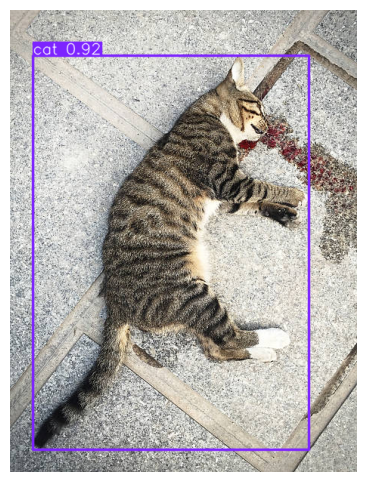

In [10]:
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

# Load YOLOv5 model
model = YOLO(r"C:\Users\Lokesh Patra\Documents\Projects\IBM ICE Day 3\yolov5xu.pt")

# Load image
image_path = r"C:\Users\Lokesh Patra\Documents\Projects\IBM ICE Day 3\Cat _ RKill.jpg"
image = cv2.imread(image_path)

# Detect dead animals
results = model(image)

# Extract detected frame
for result in results:
    im_array = result.plot()
    im_rgb = cv2.cvtColor(im_array, cv2.COLOR_BGR2RGB)

    # Display the image
    plt.figure(figsize=(10, 6))
    plt.imshow(im_rgb)
    plt.axis("off")
    plt.show()

In [11]:
#!pip install mediapipe opencv-python numpy matplotlib

In [12]:
#!pip install opencv-python numpy ultralytics matplotlib

In [13]:
def classify_risk(box, frame_width):
    """
    Classify the risk level based on the animal's position.

    Parameters:
    - box: Bounding box coordinates (x_min, y_min, x_max, y_max)
    - frame_width: Width of the video frame

    Returns:
    - Risk level: "High", "Medium", or "Low"
    """
    x_min, _, x_max, _ = box
    center_x = (x_min + x_max) / 2  # Get center of bounding box

    if frame_width * 0.3 < center_x < frame_width * 0.7:
        return "High Risk"
    elif center_x < frame_width * 0.3 or center_x > frame_width * 0.7:
        return "Medium Risk"
    else:
        return "Low Risk"


In [14]:
import cv2
import numpy as np
from ultralytics import YOLO

# Load YOLOv5 model
model = YOLO(r"C:\Users\Lokesh Patra\Documents\Projects\IBM ICE Day 3\yolov5xu.pt")

# Load input video
video_path = r"C:\Users\Lokesh Patra\Documents\Projects\IBM ICE Day 3\Dead Racoon Footage 2.mp4"
cap = cv2.VideoCapture(video_path)

# Get video properties
frame_width = int(cap.get(3))
frame_height = int(cap.get(4))
fps = int(cap.get(cv2.CAP_PROP_FPS))

# Define codec and create VideoWriter object
# r"C:\Users\Lokesh Patra\Documents\Projects\IBM ICE Day 3\output_video_SDOG.mp4"
output_path = r"C:\Users\Lokesh Patra\Documents\Projects\IBM ICE Day 3\output_video_DRac.mp4"
fourcc = cv2.VideoWriter_fourcc(*'mp4v')
out = cv2.VideoWriter(output_path, fourcc, fps, (frame_width, frame_height))

# Read the first frame
ret, prev_frame = cap.read()
prev_gray = cv2.cvtColor(prev_frame, cv2.COLOR_BGR2GRAY)

# Process video frame-by-frame
while cap.isOpened():
    ret, next_frame = cap.read()
    if not ret:
        break

    next_gray = cv2.cvtColor(next_frame, cv2.COLOR_BGR2GRAY)

    # Compute Optical Flow (Farneback method)
    flow = cv2.calcOpticalFlowFarneback(prev_gray, next_gray, None, 0.5, 3, 15, 3, 5, 1.2, 0)
    movement = np.mean(np.abs(flow))

    # Determine Alive or Dead
    motion_status = "Alive" if movement > 0.1 else "Potentially Dead"

    # Detect animals with YOLO
    results = model(next_frame)

    for result in results:
        boxes = result.boxes.xyxy.cpu().numpy()  # Get bounding boxes
        confidences = result.boxes.conf.cpu().numpy()  # Get confidence scores
        class_ids = result.boxes.cls.cpu().numpy()  # Get class IDs

        for box, conf, class_id in zip(boxes, confidences, class_ids):
            x_min, y_min, x_max, y_max = map(int, box)

            # Assign risk level
            risk_level = classify_risk(box, frame_width)

            # Draw bounding box
            color = (0, 255, 0) if motion_status == "Alive" else (0, 0, 255)  # Green for alive, Red for dead
            cv2.rectangle(next_frame, (x_min, y_min), (x_max, y_max), color, 2)

            # Display status and risk level
            label = f"{motion_status}, {risk_level} ({conf:.2f})"
            cv2.putText(next_frame, label, (x_min, y_min - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)

    # Write processed frame to output video
    out.write(next_frame)

    # Update previous frame for next iteration
    prev_gray = next_gray

cap.release()
out.release()

print(f"Processed video saved at: {output_path}")


0: 384x640 1 cat, 1 bear, 696.5ms
Speed: 2.8ms preprocess, 696.5ms inference, 1.3ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 1 bear, 680.6ms
Speed: 1.6ms preprocess, 680.6ms inference, 1.1ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 1 bear, 676.7ms
Speed: 1.7ms preprocess, 676.7ms inference, 1.2ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 1 cat, 1 bear, 701.9ms
Speed: 1.9ms preprocess, 701.9ms inference, 1.3ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 1 cat, 1 bear, 689.3ms
Speed: 1.8ms preprocess, 689.3ms inference, 1.2ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 1 cat, 1 bear, 678.7ms
Speed: 2.0ms preprocess, 678.7ms inference, 1.3ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 1 cat, 1 bear, 698.9ms
Speed: 1.9ms preprocess, 698.9ms inference, 1.3ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 1 cat, 1 bear, 712.4ms
Speed: 1.4ms preprocess, 712.4ms inference, 1.3m

In [15]:
import cv2
import numpy as np
from ultralytics import YOLO

# Load YOLOv5 model
model = YOLO(r"C:\Users\Lokesh Patra\Documents\Projects\IBM ICE Day 3\yolov5xu.pt")

# Load input video
video_path = r"C:\Users\Lokesh Patra\Documents\Projects\IBM ICE Day 3\Deer Crash Footage 3.mp4"
cap = cv2.VideoCapture(video_path)

# Get video properties
frame_width = int(cap.get(3))
frame_height = int(cap.get(4))
fps = int(cap.get(cv2.CAP_PROP_FPS))
scale_factor = 0.05  # Approximate meters per pixel (adjust based on real data)

# Define codec and create VideoWriter object
output_path = r"C:\Users\Lokesh Patra\Documents\Projects\IBM ICE Day 3\output_video_SpeeDeer.mp4"
fourcc = cv2.VideoWriter_fourcc(*'mp4v')  
out = cv2.VideoWriter(output_path, fourcc, fps, (frame_width, frame_height))

# Read the first frame
ret, prev_frame = cap.read()
prev_gray = cv2.cvtColor(prev_frame, cv2.COLOR_BGR2GRAY)

# Process video frame-by-frame
while cap.isOpened():
    ret, next_frame = cap.read()
    if not ret:
        break

    next_gray = cv2.cvtColor(next_frame, cv2.COLOR_BGR2GRAY)

    # Compute Optical Flow
    flow = cv2.calcOpticalFlowFarneback(prev_gray, next_gray, None, 0.5, 3, 15, 3, 5, 1.2, 0)

    # Calculate displacement (sum of all motion vectors)
    movement = np.mean(np.abs(flow))

    # Convert to speed (meters per second)
    speed_mps = movement * fps * scale_factor
    speed_kph = speed_mps * 3.6  # Convert to km/h

    # Detect animals with YOLO
    results = model(next_frame)

    for result in results:
        boxes = result.boxes.xyxy.cpu().numpy()  # Get bounding boxes

        for box in boxes:
            x_min, y_min, x_max, y_max = map(int, box)

            # Draw bounding box
            cv2.rectangle(next_frame, (x_min, y_min), (x_max, y_max), (255, 0, 0), 2)

            # Display speed on frame
            label = f"Speed: {speed_kph:.2f} km/h"
            cv2.putText(next_frame, label, (x_min, y_min - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 0), 2)

    # Write processed frame to output video
    out.write(next_frame)

    # Update previous frame for next iteration
    prev_gray = next_gray

cap.release()
out.release()

print(f"Processed video saved at: {output_path}")


0: 416x640 1 traffic light, 766.6ms
Speed: 1.8ms preprocess, 766.6ms inference, 1.4ms postprocess per image at shape (1, 3, 416, 640)

0: 416x640 1 traffic light, 732.8ms
Speed: 1.6ms preprocess, 732.8ms inference, 1.4ms postprocess per image at shape (1, 3, 416, 640)

0: 416x640 (no detections), 797.8ms
Speed: 2.4ms preprocess, 797.8ms inference, 1.0ms postprocess per image at shape (1, 3, 416, 640)

0: 416x640 (no detections), 733.7ms
Speed: 1.4ms preprocess, 733.7ms inference, 0.9ms postprocess per image at shape (1, 3, 416, 640)

0: 416x640 1 traffic light, 740.7ms
Speed: 1.7ms preprocess, 740.7ms inference, 1.4ms postprocess per image at shape (1, 3, 416, 640)

0: 416x640 (no detections), 728.0ms
Speed: 2.1ms preprocess, 728.0ms inference, 0.9ms postprocess per image at shape (1, 3, 416, 640)

0: 416x640 (no detections), 740.2ms
Speed: 2.2ms preprocess, 740.2ms inference, 0.9ms postprocess per image at shape (1, 3, 416, 640)

0: 416x640 (no detections), 727.5ms
Speed: 2.8ms prepr

In [16]:
import cv2
import numpy as np
import winsound  # For sound alerts (Windows users)
from ultralytics import YOLO

# Load YOLOv5 model
model = YOLO(r"C:\Users\Lokesh Patra\Documents\Projects\IBM ICE Day 3\yolov5xu.pt")

# Load input video
video_path = r"C:\Users\Lokesh Patra\Documents\Projects\IBM ICE Day 3\Dog running across the road infront of the Car Footage 4.mp4"
cap = cv2.VideoCapture(video_path)

# Ensure the video opened correctly
if not cap.isOpened():
    print("Error: Could not open video file.")
    exit()

# Get video properties
frame_width = int(cap.get(3))
frame_height = int(cap.get(4))
fps = int(cap.get(cv2.CAP_PROP_FPS))

# Define codec and create VideoWriter object
output_path = r"C:\Users\Lokesh Patra\Documents\Projects\IBM ICE Day 3\output_video_Alert.mp4"
fourcc = cv2.VideoWriter_fourcc(*'mp4v')  
out = cv2.VideoWriter(output_path, fourcc, fps, (frame_width, frame_height))

while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break

    # Detect animals with YOLO
    results = model(frame)

    for result in results:
        boxes = result.boxes.xyxy.cpu().numpy()  # Get bounding boxes

        for box in boxes:
            x_min, y_min, x_max, y_max = map(int, box)

            # Draw bounding box
            cv2.rectangle(frame, (x_min, y_min), (x_max, y_max), (0, 0, 255), 2)  # Red for alert

            # Check if animal is in the high-risk zone (center of frame)
            center_x = (x_min + x_max) / 2

            if frame_width * 0.3 < center_x < frame_width * 0.7:
                print("High-Risk Animal Detected! Sending Alert...")

                # Play an alert sound (Windows only)
                try:
                    winsound.Beep(1000, 500)
                except RuntimeError:
                    print("Beep function failed (not supported on this system).")

                # Display warning on video
                cv2.putText(frame, "HIGH-RISK ANIMAL!", (x_min, y_min - 10),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 255), 2)

    # Write processed frame to output video
    out.write(frame)

# Release resources properly
cap.release()
out.release()


print(f"Processed video saved at: {output_path}")


0: 384x640 1 car, 712.2ms
Speed: 2.3ms preprocess, 712.2ms inference, 1.1ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 1 car, 665.3ms
Speed: 1.8ms preprocess, 665.3ms inference, 1.3ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 2 cars, 666.3ms
Speed: 2.1ms preprocess, 666.3ms inference, 1.3ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 1 car, 747.8ms
Speed: 2.9ms preprocess, 747.8ms inference, 1.3ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 1 car, 663.7ms
Speed: 1.9ms preprocess, 663.7ms inference, 1.2ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 2 cars, 674.4ms
Speed: 2.0ms preprocess, 674.4ms inference, 1.3ms postprocess per image at shape (1, 3, 384, 640)
High-Risk Animal Detected! Sending Alert...

0: 384x640 2 cars, 646.4ms
Speed: 2.1ms preprocess, 646.4ms inference, 1.3ms postprocess per image at shape (1, 3, 384, 640)
High-Risk Animal Detected! Sending Alert...

0: 384x640 2 cars, 628.3ms
Speed: